# 05 · First DPO run

This notebook trains the SFT model further with **direct preference optimization (DPO)**. Each training example is a position with two answers: Stockfish's best move (*chosen*) and a legal move that loses at least 200 centipawns (*rejected*). DPO raises the probability of the chosen move relative to the rejected one.

DPO starts from the SFT model, and the SFT model is also the **reference**: the `beta` setting limits how far the trained model may move away from it. We keep training the same LoRA adapter, with the settings in `configs/dpo.yaml`.

Then it grades the DPO model exactly as notebooks 02 and 03 graded the base and SFT models.

**Before running:** run `03_sft_first_run.ipynb` (it creates `checkpoints/sft_v1/`) and `04_dpo_rl_inputs.ipynb` (it creates the preference pairs).

**Outputs**
- the adapter in `checkpoints/dpo_v1/` (not on GitHub)
- the run logs `results/dpo_v1_training.json`, `results/dpo_v1_dev.json`, and `results/dpo_v1.json`
- the figure `results/figures/dpo_v1_loss.png`

In [1]:
# Settings
RUN_NAME = "dpo_v1"
PUZZLE_LIMIT = None   # None = all puzzles. Set a small number (e.g. 5) for a quick check.

import json

import pandas as pd
import torch

from chesslm.config import REPO_ROOT, load_config
from chesslm.engine import MoveScorer
from chesslm.evaluate import evaluate, load_eval_model, save_run, summarize

model_cfg = load_config("sft")["model"]
prompt_cfg = load_config("prompt")
eval_cfg = load_config("eval")
from chesslm import plots
from chesslm.train_dpo import split_pairs, train

dpo_cfg = load_config("dpo")
lora_cfg = load_config("sft")["lora"]
START_ADAPTER = REPO_ROOT / dpo_cfg["training"]["start_adapter"]
ADAPTER_DIR = REPO_ROOT / "checkpoints" / RUN_NAME
FIGURES = REPO_ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

def run_eval(model, tokenizer, split, run_name, adapter=None):
    """Grade the model on one puzzle set, save the results, and return the summary."""
    puzzles = pd.read_csv(REPO_ROOT / "data" / "eval" / f"puzzles_{split}.csv")
    if PUZZLE_LIMIT:
        puzzles = puzzles.head(PUZZLE_LIMIT)
    with MoveScorer(eval_cfg["stockfish"]) as scorer:
        graded = evaluate(model, tokenizer, puzzles, prompt_cfg, eval_cfg["generation"], scorer)
    summary = summarize(graded)
    config = {"model": model_cfg, "adapter": adapter, "prompt": prompt_cfg, "eval": eval_cfg, "split": split}
    save_run(run_name, graded, summary, config)
    print(f"{run_name}: {len(puzzles)} puzzles | accuracy {summary['puzzle_accuracy']:.1%} | "
          f"legal {summary['legal_rate']:.1%} | ACPL {summary['acpl'] if summary['acpl'] is not None else float('nan'):.0f} | "
          f"{summary['seconds_per_position']:.2f} s per puzzle")
    return graded, summary

W1102 08:10:22.716000 41020 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


## 1. Preference pairs

The pairs built in `04_dpo_rl_inputs.ipynb`, from training positions only. We hold out 5% to watch, during training, how often the model prefers the chosen move.

In [2]:
pairs = pd.read_json(REPO_ROOT / "data" / "processed" / "dpo_pairs.jsonl", lines=True)
train_ds, val_ds = split_pairs(pairs, dpo_cfg["training"]["val_fraction"], dpo_cfg["training"]["seed"])
print(f"train: {len(train_ds):,} pairs  validation: {len(val_ds):,} pairs\n")

example = train_ds[0]
print("Prompt:  ", example["prompt"][0]["content"].replace("\n", "\n          "))
print("Chosen:  ", example["chosen"][0]["content"])
print("Rejected:", example["rejected"][0]["content"])

train: 4,549 pairs  validation: 239 pairs

Prompt:   Chess position (FEN): 2r1rk2/1b4pQ/p6p/5B2/3p1q2/PN4bP/2P5/R5K1 w - - 4 35
          White to move.
          Reply with the best move in UCI notation (for example e2e4) and nothing else.
Chosen:   h7h8
Rejected: f5d3


## 2. Training

Besides the loss, DPO reports the **preference accuracy**: the share of pairs where the model, relative to the SFT model, now favors the chosen move more than the rejected one. It starts at about 50% (the model equals the reference) and should rise.

Loading weights:   0%|          | 0/540 [00:00<?, ?it/s]

Tokenizing train dataset:   0%|          | 0/4549 [00:00<?, ? examples/s]

Dropping fully truncated examples from train dataset:   0%|          | 0/4549 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/239 [00:00<?, ? examples/s]

Dropping fully truncated examples from eval dataset:   0%|          | 0/239 [00:00<?, ? examples/s]

Step,Training Loss,Validation Loss,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
50,0.624119,0.630972,0.394280,305305.000000,-16.091377,-15.910167,0.710417,-0.285753,-0.581808,0.624405,0.296056,-6.834088,-10.810583
100,0.619930,0.616106,0.379488,610350.000000,-16.451669,-16.309958,0.700099,-0.302885,-0.644364,0.629167,0.341479,-7.005413,-11.436141
143,0.627495,0.617105,0.379397,867105.000000,-16.457210,-16.315603,0.704167,-0.301632,-0.640789,0.633333,0.339157,-6.992880,-11.400389


{
  "device": "NVIDIA GeForce RTX 5070 Ti Laptop GPU",
  "quantized_4bit": true,
  "wall_clock_minutes": 19.7,
  "gpu_hours": 0.328,
  "pairs_seen": 4549,
  "tokens_seen": 867105
}

Validation preference accuracy at the end: 63.3% (margin 0.34)


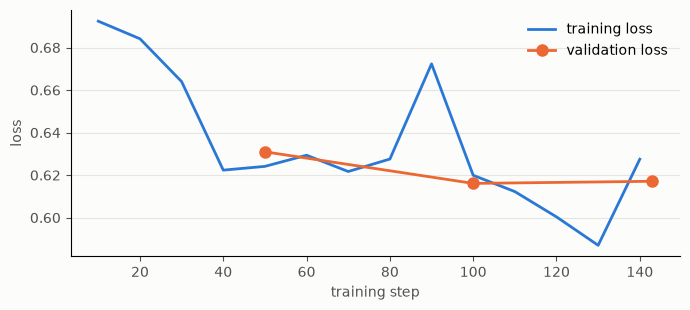

In [3]:
log, compute = train(train_ds, val_ds, dpo_cfg, model_cfg, lora_cfg, START_ADAPTER, ADAPTER_DIR)

with open(REPO_ROOT / "results" / f"{RUN_NAME}_training.json", "w") as f:
    json.dump({"config": dpo_cfg, "prompt": prompt_cfg, "start_adapter": str(START_ADAPTER), "compute": compute,
               "log": log.to_dict("records")}, f, indent=2, default=str)
print(json.dumps(compute, indent=2))

final_eval = log.dropna(subset=["eval_rewards/accuracies"]).iloc[-1]
print(f"\nValidation preference accuracy at the end: {final_eval['eval_rewards/accuracies']:.1%} "
      f"(margin {final_eval['eval_rewards/margins']:.2f})")
plots.loss_curve(log, FIGURES / f"{RUN_NAME}_loss.png");

## 3. Grade the DPO model

The same grading code, puzzles, and settings as the base and SFT models.

In [4]:
import gc

gc.collect()  # free the memory used by training before loading the model for grading
torch.cuda.empty_cache()
tokenizer, model = load_eval_model(model_cfg, adapter_path=ADAPTER_DIR)
dev_graded, dev_summary = run_eval(model, tokenizer, "dev", f"{RUN_NAME}_dev", adapter=str(ADAPTER_DIR))
test_graded, test_summary = run_eval(model, tokenizer, "test", RUN_NAME, adapter=str(ADAPTER_DIR))

Loading weights:   0%|          | 0/540 [00:00<?, ?it/s]

dpo_v1_dev: 200 puzzles | accuracy 3.5% | legal 69.5% | ACPL 853 | 0.10 s per puzzle


dpo_v1: 1000 puzzles | accuracy 5.9% | legal 63.3% | ACPL 820 | 0.10 s per puzzle


## 4. Compare with the base and SFT models

All numbers below are on the 1,000-puzzle test set.

In [5]:
summary = pd.read_csv(REPO_ROOT / "results" / "summary.csv")
runs = ["base", "sft_v1", RUN_NAME]
table = summary.set_index("run").loc[runs]

columns = {"puzzle_accuracy": "Accuracy", "accuracy_<1200": "<1200", "accuracy_1200-1800": "1200-1800",
           "accuracy_1800-2400": "1800-2400", "accuracy_2400+": "2400+", "legal_rate": "Legal",
           "illegal_rate": "Illegal", "unparseable_rate": "Unparseable", "acpl": "ACPL"}
report = table[list(columns)].rename(columns=columns)
percent = [c for c in report.columns if c != "ACPL"]
report[percent] = (report[percent] * 100).round(1)
report["ACPL"] = report["ACPL"].round(0)
report = report.astype(object).where(report.notna(), "–")  # e.g. ACPL when there are no legal moves
report

,Accuracy,<1200,1200-1800,1800-2400,2400+,Legal,Illegal,Unparseable,ACPL
run,,,,,,,,,
base,2.8,2.4,4.8,2.4,1.6,41.2,45.8,13.0,828.0
sft_v1,7.8,8.4,8.4,10.8,3.6,72.2,27.8,0.0,793.0
dpo_v1,5.9,5.2,6.0,8.0,4.4,63.3,36.7,0.0,820.0


## Summary

The DPO adapter is in `checkpoints/dpo_v1/`. Its scores and training log are in `results/`. `06_grpo_first_run.ipynb` trains the RL model and makes the comparison table and figures for all four models.